In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("housing-2.csv")

print("Dataset loaded successfully!")
df.head()


Saving housing-2.csv to housing-2.csv
Dataset loaded successfully!


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
print("First 5 rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:")
print(df.duplicated().sum())

print("\nColumn Names:")
print(df.columns.tolist())



First 5 rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Dataset Shape:
(20640, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
me

In [5]:
# Remove duplicate rows
df = df.drop_duplicates()

# Identify target column
target = "median_house_value"

# Separate input features and target
X = df.drop(columns=[target])
y = df[target]

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Column:")
print(target)

print("\nNumber of Features:", X.shape[1])

Input Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity']

Target Column:
median_house_value

Number of Features: 9


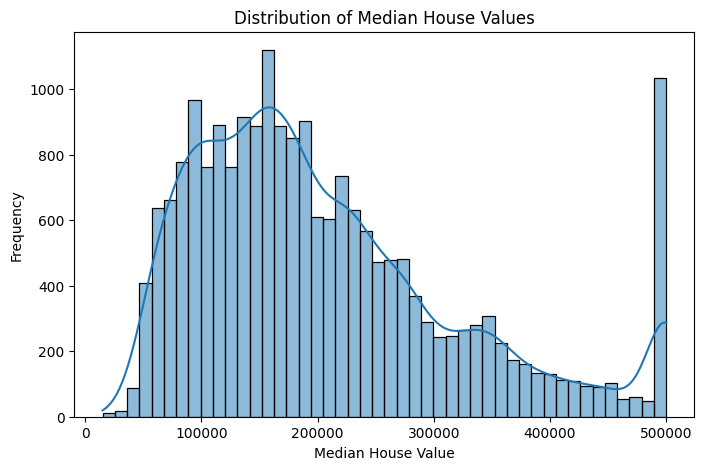

In [6]:
plt.figure(figsize=(8,5))

sns.histplot(df["median_house_value"], kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

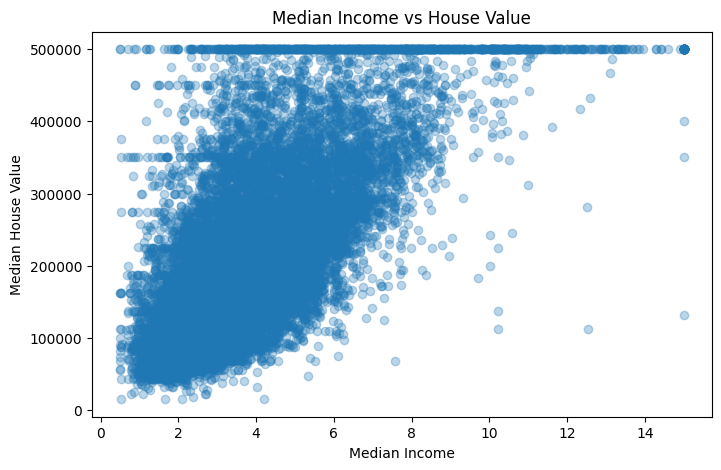

In [7]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["median_income"],
    df["median_house_value"],
    alpha=0.3
)

plt.title("Median Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

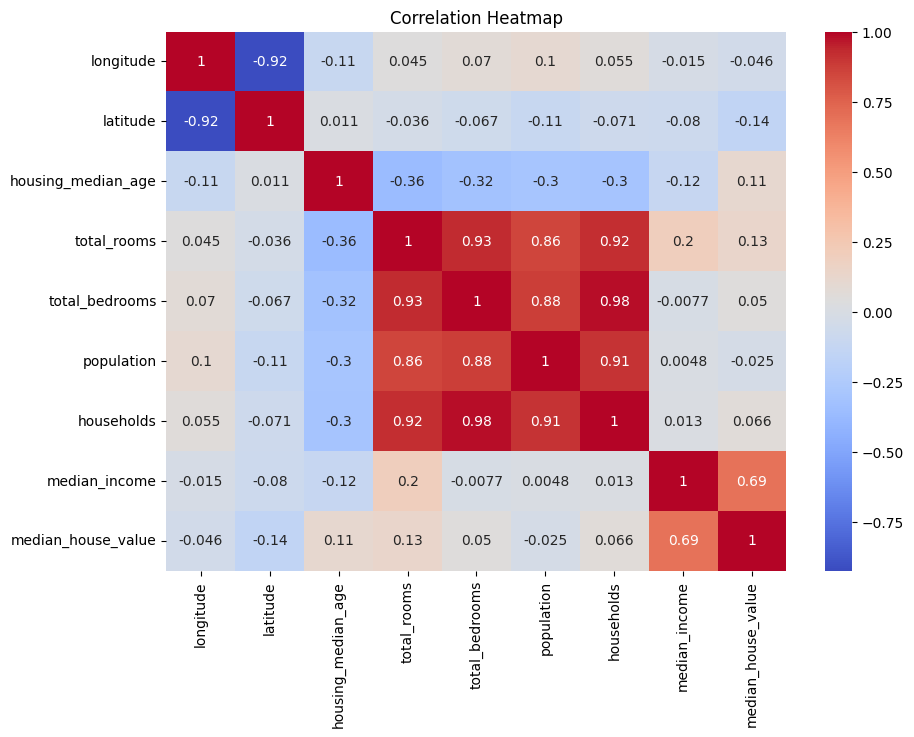

In [8]:
plt.figure(figsize=(10,7))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [9]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Separate numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Missing values handled successfully!")
print("Categorical data encoded successfully!")

Missing values handled successfully!
Categorical data encoded successfully!


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (16512, 9)
Testing Data: (4128, 9)


In [11]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [12]:
# Predict using testing data
y_pred = model.predict(X_test)

# Compare actual and predicted values
result = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(result.head(10))

   Actual Price  Predicted Price
0       47700.0     54261.027690
1       45800.0    124430.917728
2      500001.0    255694.958282
3      218600.0    268208.010360
4      278000.0    262975.013606
5      158700.0    139811.882746
6      198200.0    290871.002705
7      157500.0    228470.455166
8      340000.0    256712.364401
9      446600.0    408129.437226


In [13]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
MAE: 50670.489235653615
MSE: 4908290571.346432
RMSE: 70059.19333925014
R2 Score: 0.6254382675296266


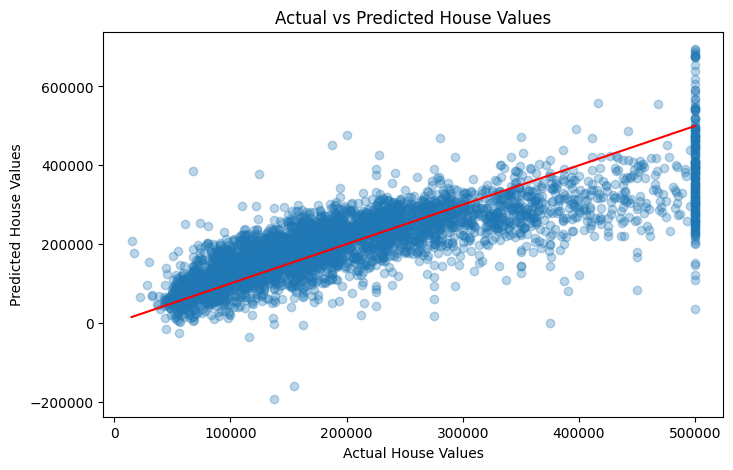

In [14]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")

plt.show()

In [15]:
# Take an existing row as a sample
new_house = X.iloc[[0]].copy()

# Change house details
new_house.loc[:, "longitude"] = -122.23
new_house.loc[:, "latitude"] = 37.88
new_house.loc[:, "housing_median_age"] = 30
new_house.loc[:, "total_rooms"] = 2000
new_house.loc[:, "total_bedrooms"] = 400
new_house.loc[:, "population"] = 800
new_house.loc[:, "households"] = 350
new_house.loc[:, "median_income"] = 5.0
new_house.loc[:, "ocean_proximity"] = "NEAR BAY"

# Predict house value
predicted_price = model.predict(new_house)

print("Predicted Median House Value:")
print(predicted_price[0])

Predicted Median House Value:
280875.2682892093
